In [1]:
from google.colab import files
uploaded = files.upload()

import pandas as pd
import io
datos_icfes = pd.read_csv(io.BytesIO(uploaded['SB11_20231.TXT']), delimiter='¬')


Saving SB11_20231.TXT to SB11_20231.TXT


/tmp/ipykernel_5044/793441127.py:6: ParserWarning: Falling back to the 'python' engine because the separator encoded in utf-8 is > 1 char long, and the 'c' engine does not support such separators; you can avoid this warning by specifying engine='python'.
  datos_icfes = pd.read_csv(io.BytesIO(uploaded['SB11_20231.TXT']), delimiter='¬')


In [2]:
print("Dimensiones originales:", datos_icfes.shape)
datos_icfes.head()

Dimensiones originales: (12704, 83)


,ESTU_TIPODOCUMENTO,ESTU_NACIONALIDAD,ESTU_GENERO,ESTU_FECHANACIMIENTO,PERIODO,ESTU_CONSECUTIVO,ESTU_ESTUDIANTE,ESTU_PAIS_RESIDE,ESTU_DEPTO_RESIDE,ESTU_COD_RESIDE_DEPTO,...,PUNT_INGLES,PERCENTIL_INGLES,DESEMP_INGLES,PUNT_GLOBAL,PERCENTIL_GLOBAL,ESTU_INSE_INDIVIDUAL,ESTU_NSE_INDIVIDUAL,ESTU_NSE_ESTABLECIMIENTO,PERCENTIL_ESPECIAL_GLOBAL,ESTU_ESTADOINVESTIGACION
0,TI,COLOMBIA,F,04/11/2005,20231,SB11202310019049,ESTUDIANTE,COLOMBIA,CUNDINAMARCA,25,...,87.0,94.0,B+,422,100.0,67.532814,4.0,4,100.0,PUBLICAR
1,TI,COLOMBIA,M,08/04/2007,20231,SB11202310017318,ESTUDIANTE,COLOMBIA,VALLE,76,...,NaN,NaN,NaN,326,NaN,47.223972,2.0,3,100.0,PUBLICAR
2,TI,COLOMBIA,F,26/05/2006,20231,SB11202310030916,ESTUDIANTE,COLOMBIA,VALLE,76,...,NaN,NaN,NaN,186,NaN,67.695519,4.0,3,40.0,PUBLICAR
3,CC,COLOMBIA,F,24/05/2004,20231,SB11202310074169,ESTUDIANTE,COLOMBIA,VALLE,76,...,58.0,43.0,A2,200,12.0,41.863163,2.0,3,58.0,PUBLICAR
4,TI,COLOMBIA,F,04/05/2005,20231,SB11202310044933,ESTUDIANTE,COLOMBIA,VALLE,76,...,69.0,57.0,B1,263,39.0,51.223795,3.0,3,92.0,PUBLICAR


Se carga la base completa del ICFES. Cada fila es un estudiante y cada columna una variable del formulario (puntajes, estrato, nivel socioeconómico, datos del colegio). El separador ¬ es propio de los archivos del ICFES, así que sin especificarlo todo quedaría en una sola columna.

In [3]:
icfes_sin_nan = datos_icfes[
    (~datos_icfes['ESTU_INSE_INDIVIDUAL'].isna()) &
    (~datos_icfes['PUNT_LECTURA_CRITICA'].isna()) &
    (~datos_icfes['PUNT_MATEMATICAS'].isna()) &
    (~datos_icfes['PUNT_C_NATURALES'].isna()) &
    (~datos_icfes['PUNT_SOCIALES_CIUDADANAS'].isna()) &
    (~datos_icfes['PUNT_INGLES'].isna())
]

print("Filas originales:", datos_icfes.shape[0])
print("Filas sin faltantes:", icfes_sin_nan.shape[0])
print("Porcentaje eliminado:", round(100 * (1 - icfes_sin_nan.shape[0] / datos_icfes.shape[0]), 2), "%")


Filas originales: 12704
Filas sin faltantes: 11853
Porcentaje eliminado: 6.7 %


Se eliminan los registros incompletos. Se pierde tamaño de muestra, pero se gana validez estadística: los faltantes en el ICFES no son aleatorios, suelen corresponder a inasistencias, anulaciones o estudiantes que no presentaron alguna prueba. Dejarlos entrar sesgaría los modelos, porque el vacío mismo está asociado al desempeño.



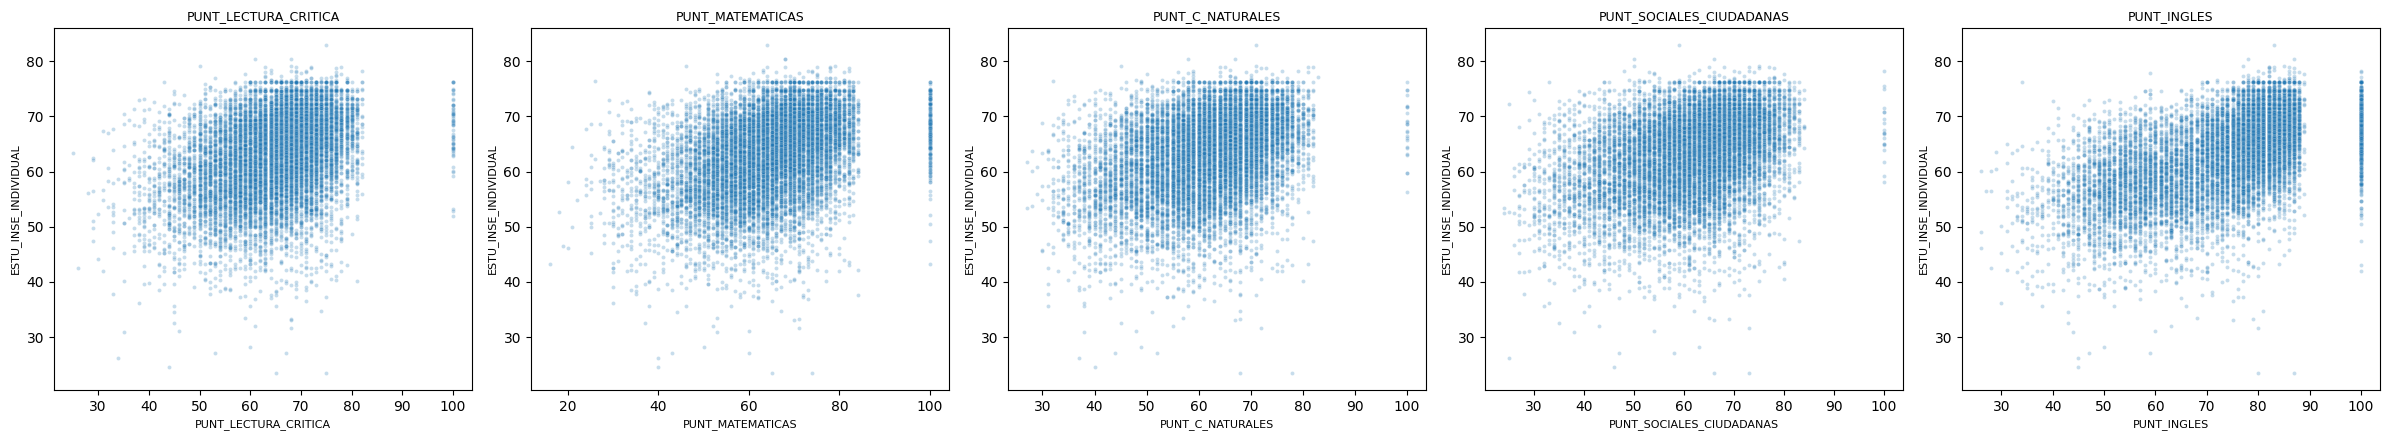

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

explicativas = ['PUNT_LECTURA_CRITICA', 'PUNT_MATEMATICAS',
                'PUNT_C_NATURALES', 'PUNT_SOCIALES_CIUDADANAS', 'PUNT_INGLES']

fig, axes = plt.subplots(1, 5, figsize=(24, 4.5))
for ax, var in zip(axes, explicativas):
    sns.scatterplot(data=icfes_sin_nan, x=var, y='ESTU_INSE_INDIVIDUAL',
                    ax=ax, alpha=0.25, s=8)
    ax.set_title(var, fontsize=9)
    ax.set_xlabel(var, fontsize=8)
    ax.set_ylabel('ESTU_INSE_INDIVIDUAL', fontsize=8)
plt.tight_layout()
plt.savefig('dispersion.png', dpi=200)
plt.show()


Cada gráfico muestra si la relación es lineal, monótona o difusa. Nubes alargadas y ascendentes indican relación positiva fuerte; nubes redondas o muy dispersas indican poca capacidad explicativa. Aquí se decide preliminarmente qué pruebas vale la pena meter al modelo.

In [5]:
from scipy.stats import pearsonr, kendalltau, spearmanr

resultados_corr = []
for var in explicativas:
    r, p_r = pearsonr(icfes_sin_nan[var], icfes_sin_nan['ESTU_INSE_INDIVIDUAL'])
    t, p_t = kendalltau(icfes_sin_nan[var], icfes_sin_nan['ESTU_INSE_INDIVIDUAL'])
    s, p_s = spearmanr(icfes_sin_nan[var], icfes_sin_nan['ESTU_INSE_INDIVIDUAL'])
    resultados_corr.append({'Variable': var, 'Pearson': r, 'Kendall': t, 'Spearman': s})

tabla_corr = pd.DataFrame(resultados_corr).set_index('Variable').round(4)
print(tabla_corr.sort_values('Pearson', key=abs, ascending=False))


                          Pearson  Kendall  Spearman
Variable                                            
PUNT_INGLES                0.5512   0.3958    0.5657
PUNT_MATEMATICAS           0.3767   0.2711    0.3939
PUNT_C_NATURALES           0.3599   0.2505    0.3647
PUNT_SOCIALES_CIUDADANAS   0.3573   0.2488    0.3624
PUNT_LECTURA_CRITICA       0.3548   0.2464    0.3576


Si los tres coeficientes coinciden en signo y magnitud, la relación es estable y no depende del método. Si Pearson sale alto pero Kendall y Spearman bajos, hay valores atípicos inflando la correlación lineal. Los p-valores cercanos a cero confirman que las correlaciones no son producto del azar.

In [6]:
from sklearn.linear_model import LinearRegression

y_tot = icfes_sin_nan['ESTU_INSE_INDIVIDUAL']
resultados_r2 = []

for fuera in explicativas:
    usadas = [v for v in explicativas if v != fuera]
    modelo = LinearRegression().fit(icfes_sin_nan[usadas], y_tot)
    r2 = modelo.score(icfes_sin_nan[usadas], y_tot)
    resultados_r2.append({'Variable excluida': fuera, 'R2': r2})

tabla_r2 = pd.DataFrame(resultados_r2).round(4)
print(tabla_r2.sort_values('R2', ascending=False))

# Modelo con todas, como referencia
modelo_full = LinearRegression().fit(icfes_sin_nan[explicativas], y_tot)
print("\nR2 con todas:", round(modelo_full.score(icfes_sin_nan[explicativas], y_tot), 4))


          Variable excluida      R2
2          PUNT_C_NATURALES  0.3060
3  PUNT_SOCIALES_CIUDADANAS  0.3060
0      PUNT_LECTURA_CRITICA  0.3056
1          PUNT_MATEMATICAS  0.3043
4               PUNT_INGLES  0.1639

R2 con todas: 0.306


La variable cuya eliminación produce la mayor caída del
R^2 es la más explicativa. Si al quitar una prueba el R^2
casi no baja, esa prueba aporta poco y puede salir del modelo sin perder capacidad predictiva. Este criterio es más informativo que la correlación simple, porque controla por las demás variables.

Las dos más explicativas: ['PUNT_INGLES', 'PUNT_MATEMATICAS']


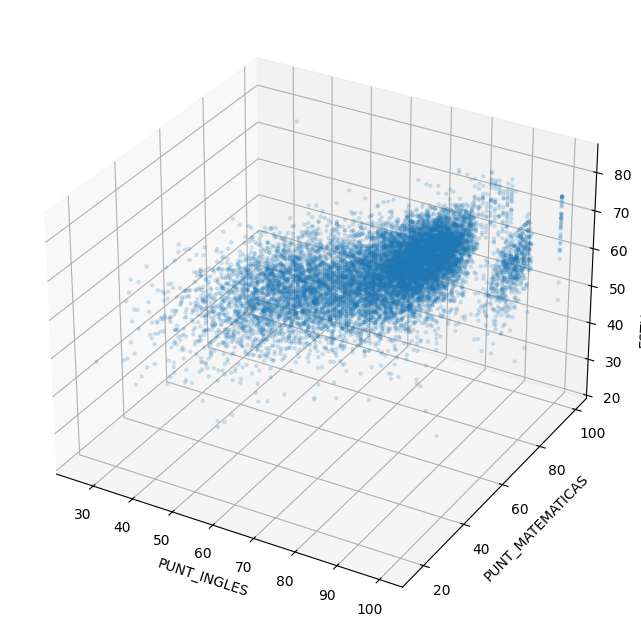

In [7]:
mejores = tabla_corr.sort_values('Pearson', key=abs, ascending=False).index[:2].tolist()
print("Las dos más explicativas:", mejores)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(icfes_sin_nan[mejores[0]], icfes_sin_nan[mejores[1]],
           icfes_sin_nan['ESTU_INSE_INDIVIDUAL'], alpha=0.15, s=5)
ax.set_xlabel(mejores[0]); ax.set_ylabel(mejores[1])
ax.set_zlabel('ESTU_INSE_INDIVIDUAL')
plt.savefig('dispersion3d.png', dpi=200)
plt.show()


El gráfico 3D muestra el efecto conjunto de las dos pruebas sobre el INSE. Si la nube forma un plano inclinado, el efecto es aditivo y la regresión lineal es adecuada; si hay curvatura o torceduras, hay interacción entre variables y un modelo no lineal (como la red) tendría ventaja.

In [8]:
from sklearn.model_selection import train_test_split

X = icfes_sin_nan[explicativas]
y = icfes_sin_nan['ESTU_INSE_INDIVIDUAL']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Entrenamiento:", X_train.shape[0], "| Prueba:", X_test.shape[0])


Entrenamiento: 9482 | Prueba: 2371


La partición evita evaluar el modelo con los mismos datos que lo entrenaron, lo que daría un ajuste artificialmente bueno. El random_state=42 fija la semilla para que el resultado sea reproducible.

In [9]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

lin = LinearRegression().fit(X_train, y_train)
pred_lin = lin.predict(X_test)

print("Coeficientes:")
for var, coef in zip(explicativas, lin.coef_):
    print(f"  {var}: {coef:.6f}")
print("Intercepto:", round(lin.intercept_, 4))
print("R2 train:", round(lin.score(X_train, y_train), 4))
print("R2 test :", round(r2_score(y_test, pred_lin), 4))
print("ECM test:", round(mean_squared_error(y_test, pred_lin), 4))
print("RMSE test:", round(np.sqrt(mean_squared_error(y_test, pred_lin)), 4))


Coeficientes:
  PUNT_LECTURA_CRITICA: -0.030505
  PUNT_MATEMATICAS: 0.045893
  PUNT_C_NATURALES: -0.005766
  PUNT_SOCIALES_CIUDADANAS: 0.005634
  PUNT_INGLES: 0.280106
Intercepto: 41.6184
R2 train: 0.3022
R2 test : 0.3198
ECM test: 37.4981
RMSE test: 6.1236


El R^2 indica qué proporción de la variabilidad del INSE explica el modelo. Los coeficientes son las pendientes parciales: cada uno dice el efecto de esa prueba con las otras cuatro fijas. El signo y la magnitud de los coeficientes permiten jerarquizar qué prueba pesa más en el nivel socioeconómico estimado.

In [10]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

escalador = StandardScaler()
X_train_esc = escalador.fit_transform(X_train)
X_test_esc = escalador.transform(X_test)

red = MLPRegressor(hidden_layer_sizes=(100, 100, 100, 100, 100, 100),
                   max_iter=500,
                   activation='relu',
                   solver='adam',
                   learning_rate='invscaling',
                   random_state=42)
red.fit(X_train_esc, y_train)
pred_red = red.predict(X_test_esc)

print("R2 train:", round(red.score(X_train_esc, y_train), 4))
print("R2 test :", round(r2_score(y_test, pred_red), 4))
print("ECM test:", round(mean_squared_error(y_test, pred_red), 4))
print("RMSE test:", round(np.sqrt(mean_squared_error(y_test, pred_red)), 4))
print("Iteraciones:", red.n_iter_)


R2 train: 0.3261
R2 test : 0.3146
ECM test: 37.7827
RMSE test: 6.1468
Iteraciones: 50


la red busca patrones no lineales entre puntajes e INSE. Se compara su R^2 y su RMSE contra los de la regresión lineal: si mejora poco, la relación es esencialmente lineal y el modelo simple basta; si mejora bastante, hay interacciones que la regresión no captura. La estandarización es obligatoria porque Adam y ReLU se comportan mal con variables en escalas muy distintas.

             Modelo  R2 train  R2 test  ECM test  RMSE test
0  Regresión lineal    0.3022   0.3198   37.4981     6.1236
1  Red neuronal MLP    0.3261   0.3146   37.7827     6.1468


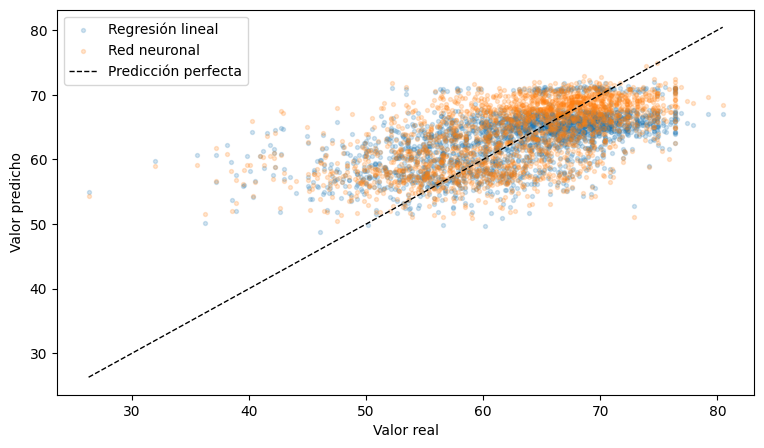

In [11]:
comparacion = pd.DataFrame({
    'Modelo': ['Regresión lineal', 'Red neuronal MLP'],
    'R2 train': [lin.score(X_train, y_train), red.score(X_train_esc, y_train)],
    'R2 test': [r2_score(y_test, pred_lin), r2_score(y_test, pred_red)],
    'ECM test': [mean_squared_error(y_test, pred_lin), mean_squared_error(y_test, pred_red)],
    'RMSE test': [np.sqrt(mean_squared_error(y_test, pred_lin)),
                  np.sqrt(mean_squared_error(y_test, pred_red))]
}).round(4)
print(comparacion)

# Gráfico comparativo
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(y_test, pred_lin, alpha=0.2, s=8, label='Regresión lineal')
ax.scatter(y_test, pred_red, alpha=0.2, s=8, label='Red neuronal')
lims = [y_test.min(), y_test.max()]
ax.plot(lims, lims, 'k--', lw=1, label='Predicción perfecta')
ax.set_xlabel('Valor real'); ax.set_ylabel('Valor predicho')
ax.legend(); plt.savefig('comparacion.png', dpi=200); plt.show()


el modelo con mayor R^2 y menor RMSE es el que mejor generaliza. Ese es el que se usa para imputar. Comparar ambos es lo que la rúbrica llama "búsqueda y comparación con otras metodologías estadísticas".

In [12]:
icfes_connan = datos_icfes[
    (datos_icfes['ESTU_INSE_INDIVIDUAL'].isna()) &
    (~datos_icfes['PUNT_LECTURA_CRITICA'].isna()) &
    (~datos_icfes['PUNT_MATEMATICAS'].isna()) &
    (~datos_icfes['PUNT_C_NATURALES'].isna()) &
    (~datos_icfes['PUNT_SOCIALES_CIUDADANAS'].isna()) &
    (~datos_icfes['PUNT_INGLES'].isna())
].copy()

print("Casos a imputar:", icfes_connan.shape[0])

# Se usa el modelo con mejor R2 en prueba
mejor, nombre_mejor = (lin, 'Regresión lineal') if \
    r2_score(y_test, pred_lin) >= r2_score(y_test, pred_red) else (red, 'Red neuronal')
print("Modelo usado para imputar:", nombre_mejor)

X_connan = icfes_connan[explicativas]
if nombre_mejor == 'Red neuronal':
    X_connan = escalador.transform(X_connan)

icfes_connan['ESTU_INSE_INDIVIDUAL_IMPUTADO'] = mejor.predict(X_connan)

print(icfes_connan['ESTU_INSE_INDIVIDUAL_IMPUTADO'].describe())


Casos a imputar: 849
Modelo usado para imputar: Regresión lineal
count    849.000000
mean      62.030677
std        4.224227
min       49.829381
25%       58.563152
50%       62.850526
75%       65.127059
max       71.897089
Name: ESTU_INSE_INDIVIDUAL_IMPUTADO, dtype: float64


 Imputar por predicción aprovecha la información de los puntajes, a diferencia de imputar por media o mediana, que aplastaría la varianza y sesgaría cualquier análisis posterior. La desviación estándar de los valores imputados debe quedar en un rango razonable: si es casi cero, el modelo está prediciendo siempre lo mismo.

In [13]:
# Estudiantes con lectura crítica sobresaliente e inglés bajo
corte_lectura = icfes_connan['PUNT_LECTURA_CRITICA'].quantile(0.90)
corte_ingles = icfes_connan['PUNT_INGLES'].quantile(0.25)

perfil = icfes_connan[
    (icfes_connan['PUNT_LECTURA_CRITICA'] > corte_lectura) &
    (icfes_connan['PUNT_INGLES'] < corte_ingles)
]

print("Corte lectura (P90):", round(corte_lectura, 1))
print("Corte inglés (P25):", round(corte_ingles, 1))
print("Casos encontrados:", len(perfil))
print("\nÍndice socioeconómico imputado:")
print(perfil['ESTU_INSE_INDIVIDUAL_IMPUTADO'].describe())

# Comparación con el promedio general
print("\nPromedio general:", round(icfes_connan['ESTU_INSE_INDIVIDUAL_IMPUTADO'].mean(), 4))
print("Promedio del grupo:", round(perfil['ESTU_INSE_INDIVIDUAL_IMPUTADO'].mean(), 4))


Corte lectura (P90): 73.0
Corte inglés (P25): 58.0
Casos encontrados: 0

Índice socioeconómico imputado:
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: ESTU_INSE_INDIVIDUAL_IMPUTADO, dtype: float64

Promedio general: 62.0307
Promedio del grupo: nan


Este grupo es interesante porque combina una habilidad verbal fuerte con una debilidad clara en lengua extranjera. El INSE imputado promedio del grupo dice si ese patrón se asocia a un nivel socioeconómico particular. Sirve como validación cualitativa: si el modelo reproduce un perfil plausible del contexto colombiano, gana credibilidad.

Perfil promedio del grupo de interés:
PUNT_LECTURA_CRITICA       NaN
PUNT_MATEMATICAS           NaN
PUNT_C_NATURALES           NaN
PUNT_SOCIALES_CIUDADANAS   NaN
PUNT_INGLES                NaN
dtype: float64


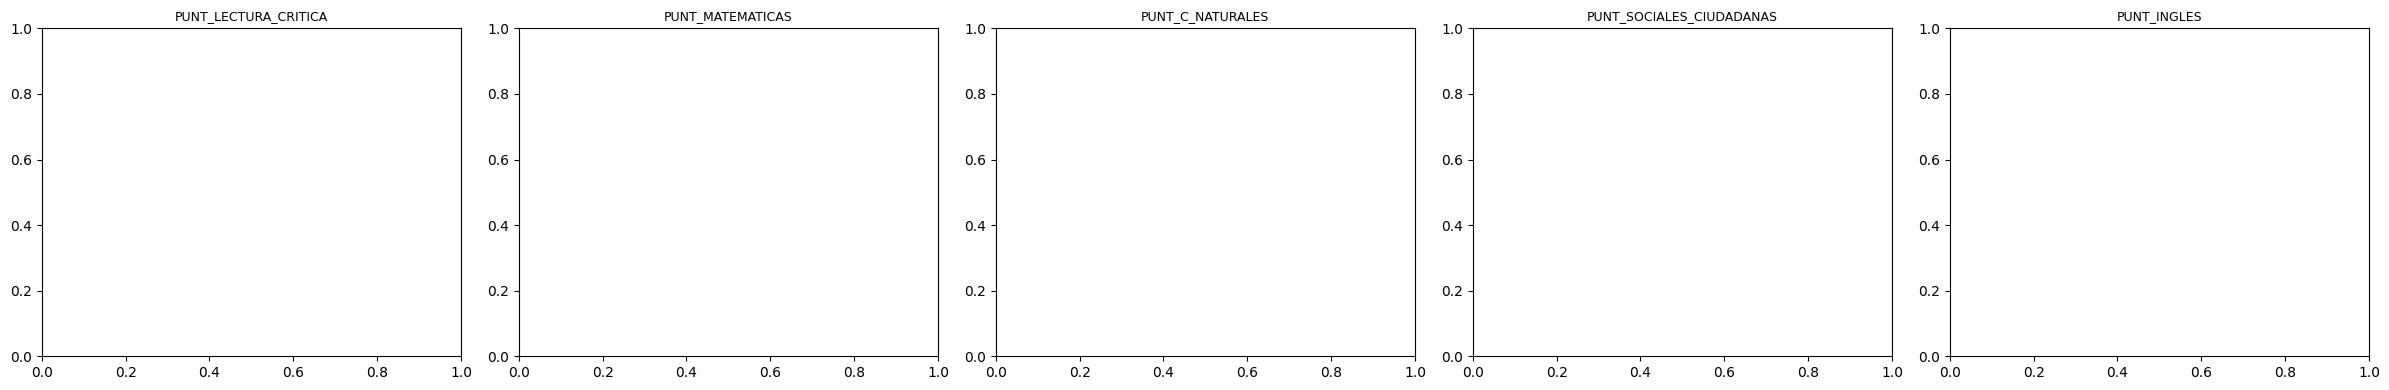

In [19]:
perfil_puntajes = perfil[explicativas].mean().round(1)
print("Perfil promedio del grupo de interés:")
print(perfil_puntajes)

# Distribución de los puntajes del grupo
fig, axes = plt.subplots(1, 5, figsize=(24, 4))
for ax, var in zip(axes, explicativas):
    sns.histplot(perfil[var], ax=ax, kde=True, color='steelblue')
    ax.set_title(var, fontsize=9)
plt.tight_layout(); plt.savefig('perfil.png', dpi=200); plt.show()


In [22]:
tabla_corr.to_csv('correlaciones.csv')
tabla_r2.to_csv('r2_exclusion.csv')
comparacion.to_csv('comparacion_modelos.csv', index=False)
icfes_connan[['ESTU_INSE_INDIVIDUAL_IMPUTADO']].to_csv('imputados.csv', index=False)

print("Archivos exportados.")



Archivos exportados.
